<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week1/lesson4/Lesson4_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 4 — Matrix Transformations: from Neural Layers to Behaviour

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 1 — Linear Algebra I\
**Lesson:** Lesson 4\
**Notebook type:** Teaching notebook

> *"A matrix is a machine: give it a vector and it hands back a new one. The same machine turns presynaptic rates into postsynaptic input, a movement into a pattern of motor-cortex firing, and that firing back into a movement."*

---

### From tables to machines

Lesson 3 treated a matrix as a **table**: rows of trials, columns of neurons. This lesson treats a matrix as a **machine** that acts on vectors. Multiplying a vector by a matrix transforms it: it can rotate, stretch, shear, flatten, or change its number of dimensions.

We will build up that view step by step: what a matrix does to one vector, what happens when two machines are chained, which machines can be undone, how a bias and a nonlinearity turn a matrix into a neural-network layer, and finally how a matrix translates between **neural space** (the firing of many neurons) and **behavioural space** (the direction of a movement), using the real motor-cortex recording from Lesson 2.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-3.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As in Lessons 1–3, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several are animated: press **Play**, drag the slider, or pick an option from the buttons.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

# Colab picks its own renderer. Elsewhere (Jupyter, VS Code), load plotly.js with each figure,
# as Colab does, so every saved figure displays on its own.
if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'

# Background gridlines off in the template used throughout.
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {
    'displaylogo': False,
    'responsive': True,
    'scrollZoom': True,
    'toImageButtonOptions': {'format': 'png', 'scale': 2},
}

def play_pause_and_slider(labels, prefix, duration=120):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-3.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[
            dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
            for k, lab in enumerate(labels)
        ],
    )]
    return buttons, sliders

# Shapes used to visualise 2-D transformations: a lattice of points, the unit square, and an asymmetric "F".
lattice = np.array([[x, y] for x in np.linspace(-1, 1, 9) for y in np.linspace(-1, 1, 9)]).T   # shape (2, 81)
unit_square = np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]], dtype=float)                         # shape (2, 5), closed outline
letter_F = np.array([[0, 0, 0.6, 0.6, 0.2, 0.2, 0.5, 0.5, 0.2, 0.2, 0],
                     [0, 1, 1, 0.8, 0.8, 0.6, 0.6, 0.4, 0.4, 0, 0]])                              # shape (2, 11), closed outline

def rotation(deg):
    t = np.radians(deg)
    return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

def draw_transform(ax, A, title, lim=2.2):
    # Draw what the 2x2 matrix A does: transformed lattice, transformed unit square, images of e1 and e2.
    pts = A @ lattice
    sq = A @ unit_square
    ax.scatter(lattice[0], lattice[1], s=4, color='lightgrey')
    ax.scatter(pts[0], pts[1], s=6, color=PALETTE[5])
    ax.fill(sq[0], sq[1], color=PALETTE[4], alpha=0.35)
    ax.plot(sq[0], sq[1], color=PALETTE[4], lw=1.2)
    for col, colour, name in [(A[:, 0], PALETTE[0], 'Ae1'), (A[:, 1], PALETTE[1], 'Ae2')]:
        ax.annotate('', xy=col, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=colour, lw=2))
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=10)

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: from one weighted sum to a whole population**

Lesson 2 modelled one neuron receiving input from four presynaptic neurons as a dot product, $z = \mathbf{w}\cdot\mathbf{r}$. Real circuits have **many** postsynaptic neurons listening to the same inputs, each with its own weights.

Four presynaptic neurons fire at $\mathbf{r} = (2,\ 5,\ 1,\ 4)$ spikes/s. Three postsynaptic neurons each compute their own weighted sum:

$$z_1 = \mathbf{w}_1\cdot\mathbf{r},\qquad z_2 = \mathbf{w}_2\cdot\mathbf{r},\qquad z_3 = \mathbf{w}_3\cdot\mathbf{r}.$$

Stack the three weight vectors as the **rows** of a matrix $\mathbf{W}$ (shape $3\times 4$: postsynaptic by presynaptic, the Lesson 3 convention), and all three dot products become one operation:

$$\mathbf{z} = \mathbf{W}\mathbf{r}.$$

In [3]:
W = np.array([[0.5, -0.2,  0.8,  0.1],
              [0.0,  0.6, -0.3,  0.4],
              [0.3,  0.3,  0.3, -0.5]])        # shape (3, 4): (postsynaptic, presynaptic), no units
r_pre = np.array([2.0, 5.0, 1.0, 4.0])         # shape (4,): presynaptic rates, spikes/s

z_loop = np.array([W[i] @ r_pre for i in range(3)])   # one Lesson 2 dot product per row
z = W @ r_pre                                          # the same three numbers in one operation

print("W shape:", W.shape, " r_pre shape:", r_pre.shape, " z shape:", z.shape)
print("Three dot products:", z_loop, "spikes/s")
print("W @ r_pre         :", z, "spikes/s")

W shape: (3, 4)  r_pre shape: (4,)  z shape: (3,)
Three dot products: [1.2 4.3 0.4] spikes/s
W @ r_pre         : [1.2 4.3 0.4] spikes/s


Postsynaptic neuron 2 receives the most input (4.3 spikes/s) because its large weights (0.6, 0.4) sit on the two most active inputs. Neuron 3 receives almost nothing: its positive weights are cancelled by the $-0.5$ on input 4.

That is the whole lesson in one line. Everything below looks at $\mathbf{W}\mathbf{r}$ from more angles: as dot products, as a mixture of columns, as a geometric transformation, as a stage in a pathway, and as a translator between brain and behaviour.

# **Part 1: The Matrix–Vector Product, Three Ways**

For a matrix $\mathbf{A}$ of shape $m\times n$ and a vector $\mathbf{x}$ with $n$ entries, the product $\mathbf{y} = \mathbf{A}\mathbf{x}$ has $m$ entries:

$$y_i = \sum_{j=1}^{n} a_{ij}\,x_j .$$

The same sum can be read three ways.

| View | Formula | Neural reading |
|---|---|---|
| **Row view** | $y_i = (\text{row } i \text{ of } \mathbf{A})\cdot\mathbf{x}$ | each output neuron computes its own weighted sum |
| **Column view** | $\mathbf{y} = x_1\mathbf{a}_{:,1} + \cdots + x_n\mathbf{a}_{:,n}$ | each input neuron contributes its own output pattern, scaled by its rate |
| **Mapping view** | $\mathbf{A}: \mathbb{R}^n \to \mathbb{R}^m$ | a machine turning $n$ input numbers into $m$ output numbers |

**The shape rule.** $(m\times n)$ times $(n,)$ gives $(m,)$. The inner sizes must agree, because each row of $\mathbf{A}$ is dotted with $\mathbf{x}$.

In [4]:
# Column view: each presynaptic neuron j contributes r_j times column j of W
contributions = W * r_pre          # shape (3, 4): column j scaled by r_pre[j] (broadcasting, Lesson 3)
z_columns = contributions.sum(axis=1)
print("Column j of W, scaled by r_j:\n", contributions)
print("Sum of the scaled columns:", z_columns, "  equals W @ r_pre?", np.allclose(z_columns, W @ r_pre))

# The shape rule in action
try:
    W @ np.ones(3)
except ValueError as err:
    print("\nW @ (a vector of length 3) fails:", err)

Column j of W, scaled by r_j:
 [[ 1.  -1.   0.8  0.4]
 [ 0.   3.  -0.3  1.6]
 [ 0.6  1.5  0.3 -2. ]]
Sum of the scaled columns: [1.2 4.3 0.4]   equals W @ r_pre? True

W @ (a vector of length 3) fails: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)


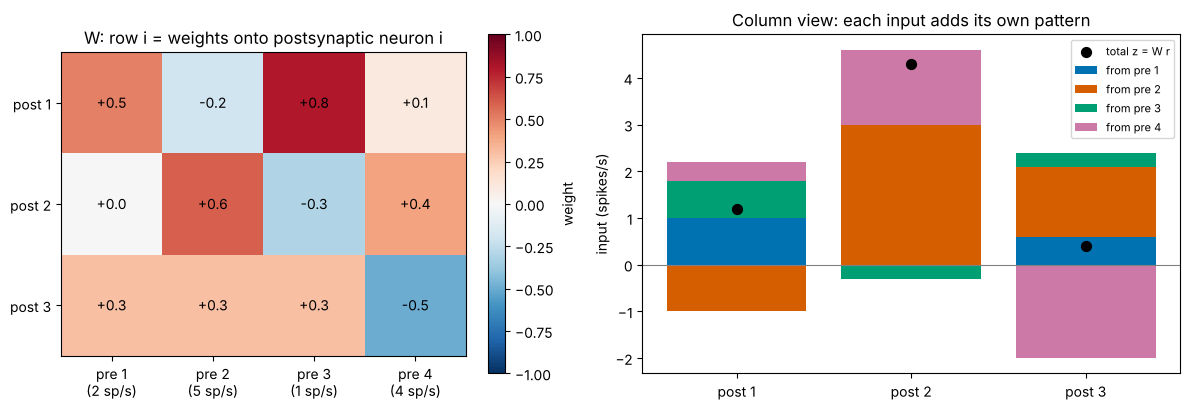

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axes[0]
im = ax.imshow(W, cmap='RdBu_r', vmin=-1, vmax=1)
for (i, j), v in np.ndenumerate(W):
    ax.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=10)
ax.set_xticks(range(4)); ax.set_xticklabels([f'pre {j + 1}\n({r_pre[j]:g} sp/s)' for j in range(4)])
ax.set_yticks(range(3)); ax.set_yticklabels([f'post {i + 1}' for i in range(3)])
ax.set_title('W: row i = weights onto postsynaptic neuron i')
plt.colorbar(im, ax=ax, fraction=0.046, label='weight')

ax = axes[1]
bottom_pos, bottom_neg = np.zeros(3), np.zeros(3)
for j in range(4):
    c = contributions[:, j]
    ax.bar(range(3), np.where(c > 0, c, 0), bottom=bottom_pos, color=PALETTE[j], label=f'from pre {j + 1}')
    ax.bar(range(3), np.where(c < 0, c, 0), bottom=bottom_neg, color=PALETTE[j])
    bottom_pos += np.where(c > 0, c, 0); bottom_neg += np.where(c < 0, c, 0)
ax.scatter(range(3), z, color='black', zorder=3, s=50, label='total z = W r')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xticks(range(3)); ax.set_xticklabels([f'post {i + 1}' for i in range(3)])
ax.set_ylabel('input (spikes/s)')
ax.set_title('Column view: each input adds its own pattern')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

#### Animation: building $\mathbf{W}\mathbf{r}$ one column at a time

In [6]:
# INTERACTIVE ANIMATION -- add the presynaptic neurons' contributions one at a time
partial = np.vstack([np.zeros(3), np.cumsum(contributions, axis=1).T])   # shape (5, 3): running total after 0..4 inputs
fig_cols = go.Figure(go.Bar(x=['post 1', 'post 2', 'post 3'], y=partial[0], marker_color=PALETTE[0],
                            hovertemplate='%{x}: %{y:.2f} spikes/s<extra></extra>'))
fig_cols.add_trace(go.Scatter(x=['post 1', 'post 2', 'post 3'], y=z, mode='markers', name='final W r',
                              marker=dict(color='black', size=12, symbol='x')))
fig_cols.frames = [go.Frame(name=str(k), data=[go.Bar(y=partial[k])],
                            layout=go.Layout(title=f'Running total after adding {k} presynaptic neuron(s)'))
                   for k in range(5)]
buttons, sliders = play_pause_and_slider([f'{k} inputs' for k in range(5)], prefix='', duration=700)
fig_cols.update_layout(title='Running total after adding 0 presynaptic neuron(s)', yaxis=dict(title='input (spikes/s)', range=[-1.5, 5]),
                       template='plotly_white', width=700, height=480, showlegend=False,
                       updatemenus=buttons, sliders=sliders)
fig_cols.show(config=PLOTLY_CONFIG)

**Try it.** Silence presynaptic neuron 2 (set `r_pre[1] = 0`) and predict, using the column view, how each postsynaptic input changes before you rerun. Column 2 of `W` is $(-0.2,\ 0.6,\ 0.3)$, so removing $5\times$ that column lowers neuron 2 by 3 spikes/s and raises neuron 1 by 1.

# **Part 2: The Matrix–Matrix Product**

To multiply two matrices, apply the row view to every column of the second one. For $\mathbf{A}$ of shape $m\times k$ and $\mathbf{B}$ of shape $k\times n$, the product $\mathbf{C} = \mathbf{A}\mathbf{B}$ has shape $m\times n$ and entries

$$c_{ij} = \sum_{l=1}^{k} a_{il}\,b_{lj} = (\text{row } i \text{ of } \mathbf{A})\cdot(\text{column } j \text{ of } \mathbf{B}).$$

Two equivalent readings:
- **entry by entry**: every entry is one dot product;
- **column by column**: column $j$ of $\mathbf{C}$ is $\mathbf{A}$ applied to column $j$ of $\mathbf{B}$, so $\mathbf{A}\mathbf{B}$ is "$\mathbf{A}$ acting on every column of $\mathbf{B}$ at once".

**Shape contract:** $(m\times k)(k\times n) = (m\times n)$. The inner sizes must match; the outer sizes survive.

In [7]:
A = np.array([[1.0, 0.0, 2.0],
              [-1.0, 3.0, 1.0]])     # shape (2, 3)
B = np.array([[3.0, 1.0],
              [2.0, 1.0],
              [1.0, 0.0]])           # shape (3, 2)
C_AB = A @ B                         # shape (2, 2)

print("A @ B =\n", C_AB)
print("Entry (1, 2) by hand: row 1 of A . column 2 of B =", A[0] @ B[:, 1])
print("Column 2 of A @ B equals A @ (column 2 of B)?", np.allclose(C_AB[:, 1], A @ B[:, 1]))
print("B @ A has shape", (B @ A).shape, "-- a different matrix of a different shape")

A @ B =
 [[5. 1.]
 [4. 2.]]
Entry (1, 2) by hand: row 1 of A . column 2 of B = 1.0
Column 2 of A @ B equals A @ (column 2 of B)? True
B @ A has shape (3, 3) -- a different matrix of a different shape


### Batches of trials: one product instead of a loop

In Lesson 3 a recording was a matrix $\mathbf{X}$ with **one trial per row**. To send every trial through the weights $\mathbf{W}$ (shape outputs $\times$ inputs), each row $\mathbf{x}_t$ must be multiplied by $\mathbf{W}$. Written for all trials at once, with trials as rows, that is

$$\mathbf{Z} = \mathbf{X}\mathbf{W}^{\mathsf T}, \qquad (T\times n)(n\times m) = (T\times m).$$

The transpose lines up the shared input axis. Row $t$ of $\mathbf{Z}$ is $\mathbf{W}\mathbf{x}_t$, the output for trial $t$.

In [8]:
X_trials = RNG.poisson(lam=[2.0, 5.0, 1.0, 4.0], size=(50, 4)).astype(float)   # shape (50, 4): (trial, presynaptic), spikes/s
Z_batch = X_trials @ W.T                                                          # shape (50, 3): (trial, postsynaptic)
Z_loop = np.array([W @ x for x in X_trials])

print("X_trials:", X_trials.shape, " W.T:", W.T.shape, " Z_batch:", Z_batch.shape)
print("Batch product equals the loop?", np.allclose(Z_batch, Z_loop))
print("Trial 1 input:", X_trials[0], "-> output:", np.round(Z_batch[0], 2))

X_trials: (50, 4)  W.T: (4, 3)  Z_batch: (50, 3)
Batch product equals the loop? True
Trial 1 input: [4. 8. 1. 4.] -> output: [1.6 6.1 1.9]


### Two rules: grouping is free, order is not

**Associative:** $(\mathbf{A}\mathbf{B})\mathbf{C} = \mathbf{A}(\mathbf{B}\mathbf{C})$. You may group a chain of products however is convenient.

**Not commutative:** in general $\mathbf{A}\mathbf{B} \neq \mathbf{B}\mathbf{A}$, even when both exist and have the same shape.

Associativity has a practical side. For a $1000\times1000$ pair of matrices and a vector, $(\mathbf{A}\mathbf{B})\mathbf{x}$ first builds a whole new matrix (about $10^9$ multiplications), while $\mathbf{A}(\mathbf{B}\mathbf{x})$ needs only two matrix–vector products (about $2\times10^6$). Same answer, 500 times less work.

In [9]:
P = np.array([[2.0, 0.0], [1.0, 3.0]])
Q = np.array([[1.0, 4.0], [2.0, 1.0]])
R3 = np.array([[0.0, 1.0], [-1.0, 2.0]])

print("(P Q) R3 equals P (Q R3)?", np.allclose((P @ Q) @ R3, P @ (Q @ R3)))
print("P Q =\n", P @ Q)
print("Q P =\n", Q @ P)
print("P Q equals Q P?", np.allclose(P @ Q, Q @ P))

n_big = 1000
mults_left = n_big**3 + n_big**2       # (A B) first, then times x
mults_right = 2 * n_big**2             # B x first, then A times that
print(f"\nMultiplications for (A B) x: {mults_left:.1e};  for A (B x): {mults_right:.1e}  (ratio {mults_left / mults_right:.0f})")

(P Q) R3 equals P (Q R3)? True
P Q =
 [[2. 8.]
 [7. 7.]]
Q P =
 [[ 6. 12.]
 [ 5.  3.]]
P Q equals Q P? False

Multiplications for (A B) x: 1.0e+09;  for A (B x): 2.0e+06  (ratio 500)


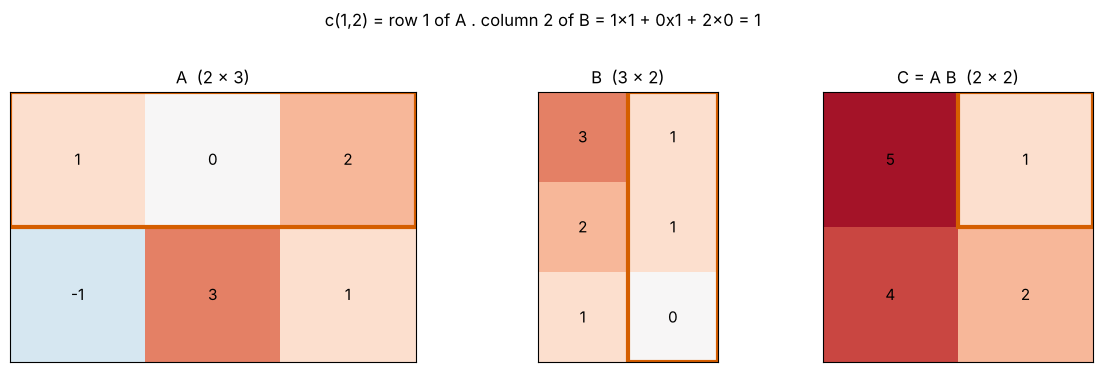

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={'width_ratios': [3, 2, 2]})
for ax, M, name in zip(axes, [A, B, C_AB], ['A  (2 x 3)', 'B  (3 x 2)', 'C = A B  (2 x 2)']):
    ax.imshow(M, cmap='RdBu_r', vmin=-6, vmax=6)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:g}', ha='center', va='center', fontsize=11)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(name)
axes[0].add_patch(plt.Rectangle((-0.5, -0.5), 3, 1, fill=False, ec=PALETTE[1], lw=3))
axes[1].add_patch(plt.Rectangle((0.5, -0.5), 1, 3, fill=False, ec=PALETTE[1], lw=3))
axes[2].add_patch(plt.Rectangle((0.5, -0.5), 1, 1, fill=False, ec=PALETTE[1], lw=3))
fig.suptitle('c(1,2) = row 1 of A . column 2 of B = 1x1 + 0x1 + 2x0 = 1', y=1.02)
plt.tight_layout()
plt.show()

#### Interactive version: hover over any entry of $\mathbf{C}$ to see its dot product

In [11]:
hover = [[' + '.join(f'{A[i, l]:g}x{B[l, j]:g}' for l in range(3)) + f' = {C_AB[i, j]:g}' for j in range(2)] for i in range(2)]
fig_mm = go.Figure(go.Heatmap(z=C_AB, x=['col 1', 'col 2'], y=['row 1', 'row 2'], colorscale='RdBu', reversescale=True, zmid=0,
                              text=hover, hovertemplate='%{y}, %{x}:<br>%{text}<extra></extra>'))
fig_mm.update_yaxes(autorange='reversed')
fig_mm.update_layout(title='C = A B: each entry is (row of A) . (column of B)', template='plotly_white', width=520, height=420)
fig_mm.show(config=PLOTLY_CONFIG)

# **Part 3: Matrices as Linear Transformations**

A function $T$ from vectors to vectors is **linear** if it respects addition and scaling:

$$T(\mathbf{u} + \mathbf{v}) = T(\mathbf{u}) + T(\mathbf{v}), \qquad T(c\,\mathbf{u}) = c\,T(\mathbf{u}).$$

Multiplying by a matrix is always linear. The reverse is also true: **every** linear function between vectors is multiplication by some matrix, and that matrix can be read off directly.

> **The columns of $\mathbf{A}$ are where the basis vectors go.** Column 1 is $\mathbf{A}\mathbf{e}_1$ and column 2 is $\mathbf{A}\mathbf{e}_2$. Since every $\mathbf{x} = x_1\mathbf{e}_1 + x_2\mathbf{e}_2$ (Lesson 1), linearity forces $\mathbf{A}\mathbf{x} = x_1\mathbf{A}\mathbf{e}_1 + x_2\mathbf{A}\mathbf{e}_2$: the column view of Part 1.

In two dimensions we can **see** a transformation by watching what it does to a lattice of points and to the unit square.

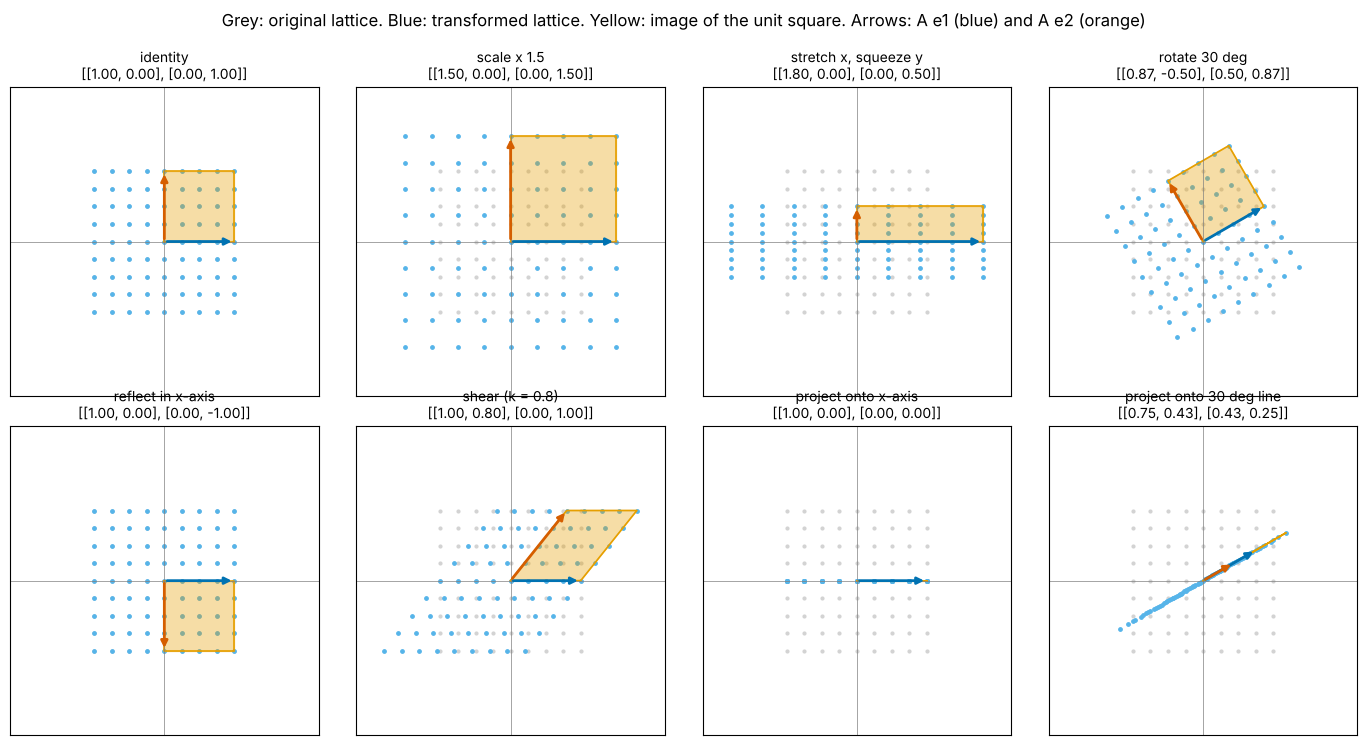

transformation              keeps lengths?  keeps angles?  area factor
identity                              True           True         1.00
scale x 1.5                          False           True         2.25
stretch x, squeeze y                 False          False         0.90
rotate 30 deg                         True           True         1.00
reflect in x-axis                     True           True         1.00
shear (k = 0.8)                      False          False         1.00
project onto x-axis                  False          False         0.00
project onto 30 deg line             False          False         0.00


In [12]:
gallery = {
    'identity': np.eye(2),
    'scale x 1.5': 1.5 * np.eye(2),
    'stretch x, squeeze y': np.diag([1.8, 0.5]),
    'rotate 30 deg': rotation(30),
    'reflect in x-axis': np.diag([1.0, -1.0]),
    'shear (k = 0.8)': np.array([[1.0, 0.8], [0.0, 1.0]]),
    'project onto x-axis': np.array([[1.0, 0.0], [0.0, 0.0]]),
    'project onto 30 deg line': np.outer([np.cos(np.radians(30)), np.sin(np.radians(30))], [np.cos(np.radians(30)), np.sin(np.radians(30))]),
}

fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for ax, (name, M) in zip(axes.ravel(), gallery.items()):
    draw_transform(ax, M, f'{name}\n[[{M[0, 0]:.2f}, {M[0, 1]:.2f}], [{M[1, 0]:.2f}, {M[1, 1]:.2f}]]')
fig.suptitle('Grey: original lattice. Blue: transformed lattice. Yellow: image of the unit square. Arrows: A e1 (blue) and A e2 (orange)', y=1.0)
plt.tight_layout()
plt.show()

print(f"{'transformation':<26}{'keeps lengths?':>16}{'keeps angles?':>15}{'area factor':>13}")
u_test, v_test = np.array([1.0, 0.0]), np.array([0.6, 0.8])
for name, M in gallery.items():
    keeps_len = np.isclose(np.linalg.norm(M @ v_test), np.linalg.norm(v_test)) and np.isclose(np.linalg.norm(M @ u_test), 1)
    cos_before = u_test @ v_test
    Mu, Mv = M @ u_test, M @ v_test
    keeps_ang = np.linalg.norm(Mv) > 0 and np.isclose(Mu @ Mv / (np.linalg.norm(Mu) * np.linalg.norm(Mv) + 1e-12), cos_before)
    print(f"{name:<26}{str(keeps_len):>16}{str(bool(keeps_ang)):>15}{abs(np.linalg.det(M)):>13.2f}")

Only the identity, the rotation and the reflection keep every length and angle: they move the plane rigidly. A uniform scaling keeps angles but changes lengths (it zooms). Unequal scalings and shears distort shape. The projections **flatten** the whole plane onto a line: their area factor is 0, and many different inputs land on the same output.

The **area factor** printed in the last column is how much the matrix multiplies areas: the unit square (area 1) becomes a parallelogram of that area. For a $2\times2$ matrix it equals $|ad - bc|$, the absolute value of the **determinant** (the study notes prove it). It will matter in Part 6.

#### Interactive version: pick a transformation

In [13]:
# INTERACTIVE -- buttons switch between the transformations
def transform_traces(M):
    pts, sq = M @ lattice, M @ unit_square
    return [dict(x=pts[0], y=pts[1]), dict(x=sq[0], y=sq[1]), dict(x=[0, M[0, 0]], y=[0, M[1, 0]]), dict(x=[0, M[0, 1]], y=[0, M[1, 1]])]

first = gallery['identity']
init = transform_traces(first)
fig_gal = go.Figure([
    go.Scatter(**init[0], mode='markers', marker=dict(color=PALETTE[5], size=5), name='lattice'),
    go.Scatter(**init[1], mode='lines', fill='toself', line=dict(color=PALETTE[4]), name='unit square'),
    go.Scatter(**init[2], mode='lines+markers', line=dict(color=PALETTE[0], width=4), name='A e1'),
    go.Scatter(**init[3], mode='lines+markers', line=dict(color=PALETTE[1], width=4), name='A e2'),
])
buttons = []
for name, M in gallery.items():
    tr = transform_traces(M)
    buttons.append(dict(label=name, method='update',
                        args=[{'x': [t['x'] for t in tr], 'y': [t['y'] for t in tr]},
                              {'title': f'{name}:  A = [[{M[0, 0]:.2f}, {M[0, 1]:.2f}], [{M[1, 0]:.2f}, {M[1, 1]:.2f}]],  area factor {abs(np.linalg.det(M)):.2f}'}]))
fig_gal.update_layout(updatemenus=[dict(type='buttons', direction='down', x=1.02, y=1, xanchor='left', buttons=buttons)],
                      title='identity:  A = [[1.00, 0.00], [0.00, 1.00]],  area factor 1.00',
                      xaxis=dict(range=[-2.2, 2.2], zeroline=True), yaxis=dict(range=[-2.2, 2.2], scaleanchor='x', scaleratio=1, zeroline=True),
                      template='plotly_white', width=860, height=600)
fig_gal.show(config=PLOTLY_CONFIG)

**Try it.** Build your own matrix by deciding where $\mathbf{e}_1$ and $\mathbf{e}_2$ should go: for example $\mathbf{A}\mathbf{e}_1 = (1, 1)$ and $\mathbf{A}\mathbf{e}_2 = (-1, 1)$. Write those as the columns, then draw it with `draw_transform`. What does it do? (Rotate by 45° and stretch by $\sqrt 2$.)

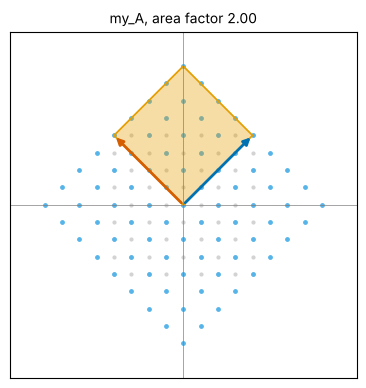

In [14]:
# EDIT the two columns and rerun
my_A = np.column_stack([[1.0, 1.0], [-1.0, 1.0]])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_transform(ax, my_A, f'my_A, area factor {abs(np.linalg.det(my_A)):.2f}', lim=2.5)
plt.show()

# **Part 4: Composition — Doing One Transformation After Another**

If $\mathbf{x}$ is first transformed by $\mathbf{S}$ and the result is then transformed by $\mathbf{R}$, the output is

$$\mathbf{R}(\mathbf{S}\mathbf{x}) = (\mathbf{R}\mathbf{S})\mathbf{x}.$$

So chaining two linear stages is itself one linear stage, with matrix $\mathbf{R}\mathbf{S}$. Read it **right to left**: the matrix next to $\mathbf{x}$ acts first.

Because matrix multiplication is not commutative, the order matters. Below, $\mathbf{S}$ stretches $x$ by 1.8 and squeezes $y$ to 0.5, and $\mathbf{R}$ rotates by 35°. "Stretch, then rotate" ($\mathbf{R}\mathbf{S}$) and "rotate, then stretch" ($\mathbf{S}\mathbf{R}$) give different shapes.

R (S x) equals (R S) x? True
R S =
 [[ 1.474 -0.287]
 [ 1.032  0.41 ]] 
S R =
 [[ 1.474 -1.032]
 [ 0.287  0.41 ]]


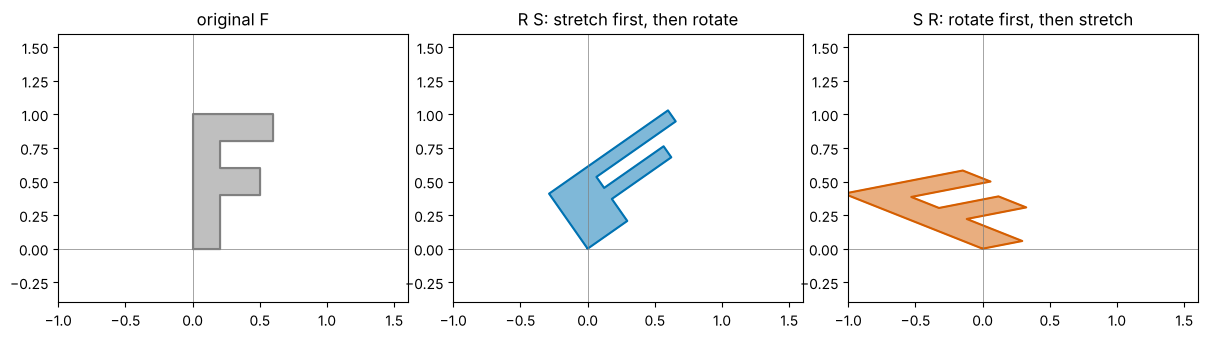

In [15]:
S_stretch = np.diag([1.8, 0.5])
R_rot = rotation(35)
RS, SR = R_rot @ S_stretch, S_stretch @ R_rot

x_check = np.array([0.4, 1.0])
print("R (S x) equals (R S) x?", np.allclose(R_rot @ (S_stretch @ x_check), RS @ x_check))
print("R S =\n", np.round(RS, 3), "\nS R =\n", np.round(SR, 3))

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, M, title, colour in [(axes[0], np.eye(2), 'original F', 'grey'),
                             (axes[1], RS, 'R S: stretch first, then rotate', PALETTE[0]),
                             (axes[2], SR, 'S R: rotate first, then stretch', PALETTE[1])]:
    shape = M @ letter_F
    ax.fill(shape[0], shape[1], color=colour, alpha=0.5); ax.plot(shape[0], shape[1], color=colour)
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlim(-1, 1.6); ax.set_ylim(-0.4, 1.6); ax.set_aspect('equal'); ax.set_title(title)
plt.tight_layout()
plt.show()

#### Animation: the two orders, step by step

In [16]:
# INTERACTIVE ANIMATION -- each stage is applied gradually: stretch amount and rotation angle grow from 0 to full
def stretch(t): return np.diag([1 + 0.8 * t, 1 - 0.5 * t])
steps = np.linspace(0, 1, 15)
path_RS = [stretch(t) for t in steps] + [rotation(35 * t) @ stretch(1) for t in steps]   # stretch, then rotate
path_SR = [rotation(35 * t) for t in steps] + [stretch(t) @ rotation(35) for t in steps]   # rotate, then stretch
labels = [f'stage 1 ({k + 1}/15)' for k in range(15)] + [f'stage 2 ({k + 1}/15)' for k in range(15)]

fig_comp = make_subplots(rows=1, cols=2, subplot_titles=('R S: stretch, then rotate', 'S R: rotate, then stretch'))
for col, colour in [(1, PALETTE[0]), (2, PALETTE[1])]:
    fig_comp.add_trace(go.Scatter(x=letter_F[0], y=letter_F[1], mode='lines', line=dict(color='lightgrey'), showlegend=False), row=1, col=col)
    fig_comp.add_trace(go.Scatter(x=letter_F[0], y=letter_F[1], mode='lines', fill='toself', line=dict(color=colour), showlegend=False), row=1, col=col)
fig_comp.frames = [go.Frame(name=str(k), traces=[1, 3], data=[go.Scatter(x=(M1 @ letter_F)[0], y=(M1 @ letter_F)[1]),
                                                             go.Scatter(x=(M2 @ letter_F)[0], y=(M2 @ letter_F)[1])])
                   for k, (M1, M2) in enumerate(zip(path_RS, path_SR))]
buttons, sliders = play_pause_and_slider(labels, prefix='', duration=80)
for col in (1, 2):
    fig_comp.update_xaxes(range=[-1, 1.8], row=1, col=col)
    fig_comp.update_yaxes(range=[-0.5, 1.6], scaleanchor=f'x{"" if col == 1 else 2}', scaleratio=1, row=1, col=col)
fig_comp.update_layout(template='plotly_white', width=950, height=500, updatemenus=buttons, sliders=sliders,
                       title='Same two matrices, different order, different result')
fig_comp.show(config=PLOTLY_CONFIG)

**In a neural pathway.** If $\mathbf{W}_1$ maps retinal activity to thalamic (LGN) activity and $\mathbf{W}_2$ maps LGN to visual cortex (V1), a purely linear version of the pathway is $\mathbf{r}_{V1} = \mathbf{W}_2\mathbf{W}_1\,\mathbf{r}_{\text{retina}}$: the stage nearest the input is written last. Real pathways are nonlinear and recurrent; this is the linear skeleton only (Part 7 adds the nonlinearity).

**Common pitfall.** "$\mathbf{A}\mathbf{B}$ means do $\mathbf{A}$ first" is backwards. In $(\mathbf{A}\mathbf{B})\mathbf{x} = \mathbf{A}(\mathbf{B}\mathbf{x})$, $\mathbf{B}$ touches $\mathbf{x}$ first.

# **Part 5: Changing Dimension, and the Idea of Rank**

A matrix of shape $m\times n$ takes vectors with $n$ entries to vectors with $m$ entries. The two dimensions need not match.

- A **tall** matrix ($m > n$) **embeds**: it takes a low-dimensional input into a higher-dimensional space. Two stimulus features driving 3 neurons is a $3\times2$ map.
- A **wide** matrix ($m < n$) **compresses**: it reads many numbers down to few. A readout of 3 neurons onto 2 behavioural variables is a $2\times3$ map.

Whatever the shape, every output $\mathbf{A}\mathbf{x}$ is a combination of the **columns** of $\mathbf{A}$ (Part 1). So the set of all possible outputs, the **image** of $\mathbf{A}$, is the set of all combinations of its columns. The **rank** of $\mathbf{A}$ is the number of independent directions in that image:

> **rank = how many dimensions the outputs can actually fill.**

The rank can never exceed the number of columns (there are only that many to combine) or the number of rows (the outputs live in $m$ dimensions). So $\operatorname{rank}(\mathbf{A}) \le \min(m, n)$.

In [17]:
A_up = np.array([[1.0, 0.0],
                 [0.0, 1.0],
                 [0.8, -0.6]])            # shape (3, 2): 2 stimulus features -> 3 neurons
A_down = A_up.T                           # shape (2, 3): 3 neurons -> 2 readout variables
A_dependent = np.array([[1.0, 2.0, 3.0],
                        [0.0, 1.0, 1.0],
                        [1.0, 3.0, 4.0]]) # column 3 = column 1 + column 2

for name, M in [('A_up (3x2)', A_up), ('A_down (2x3)', A_down), ('A_dependent (3x3)', A_dependent),
                ('projection onto x-axis (2x2)', gallery['project onto x-axis']), ('rotation (2x2)', R_rot)]:
    print(f"{name:<30} rank {np.linalg.matrix_rank(M)}")

# A_down sends a whole line of different inputs to the same output
n_dir = np.array([-0.8, 0.6, 1.0])           # A_down @ n_dir = 0
x0 = np.array([1.0, 2.0, 0.5])
print("\nA_down @ n_dir =", A_down @ n_dir)
for t in [0, 2, 5]:
    print(f"input {np.round(x0 + t * n_dir, 2)} -> output {A_down @ (x0 + t * n_dir)}")

A_up (3x2)                     rank 2
A_down (2x3)                   rank 2
A_dependent (3x3)              rank 2
projection onto x-axis (2x2)   rank 1
rotation (2x2)                 rank 2

A_down @ n_dir = [0. 0.]
input [1.  2.  0.5] -> output [1.4 1.7]
input [-0.6  3.2  2.5] -> output [1.4 1.7]
input [-3.   5.   5.5] -> output [1.4 1.7]


`A_dependent` is $3\times3$ but has rank 2: its third column is the sum of the first two, so it adds no new direction, and every output lies in a plane. `A_down` has rank 2 and maps 3 dimensions onto 2, so a whole **line** of inputs, $\mathbf{x}_0 + t\,\mathbf{n}$, collapses to one output. Those inputs differ, but the readout cannot tell them apart. That loss is permanent: no later matrix can recover which input it was.

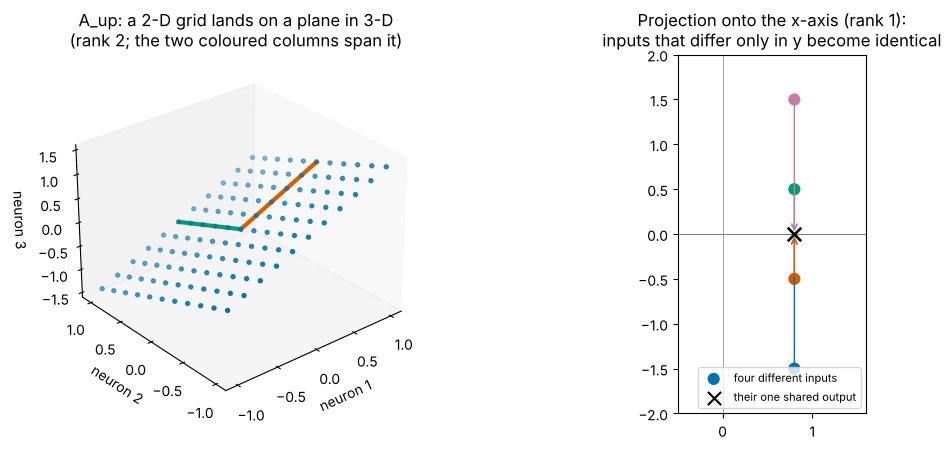

In [18]:
uv = np.array([[a, b] for a in np.linspace(-1, 1, 11) for b in np.linspace(-1, 1, 11)]).T   # shape (2, 121): a 2-D grid of inputs
image_up = A_up @ uv                                                                        # shape (3, 121): outputs in 3-D

fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(image_up[0], image_up[1], image_up[2], s=8, color=PALETTE[0])
for col, colour in [(A_up[:, 0], PALETTE[1]), (A_up[:, 1], PALETTE[2])]:
    ax.plot([0, col[0]], [0, col[1]], [0, col[2]], color=colour, lw=3)
ax.set_xlabel('neuron 1'); ax.set_ylabel('neuron 2'); ax.set_zlabel('neuron 3')
ax.set_title('A_up: a 2-D grid lands on a plane in 3-D\n(rank 2; the two coloured columns span it)')
ax.grid(False)
ax.view_init(elev=28, azim=-130)

ax = fig.add_subplot(1, 2, 2)
P_x = gallery['project onto x-axis']
pts_in = np.array([[0.8, 0.8, 0.8, 0.8], [-1.5, -0.5, 0.5, 1.5]])
ax.scatter(pts_in[0], pts_in[1], color=PALETTE[:4], s=60, zorder=3, label='four different inputs')
ax.scatter(*(P_x @ pts_in), color='black', marker='x', s=90, zorder=4, label='their one shared output')
for k in range(4):
    ax.annotate('', xy=P_x @ pts_in[:, k], xytext=pts_in[:, k], arrowprops=dict(arrowstyle='->', color=PALETTE[k]))
ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlim(-0.5, 1.6); ax.set_ylim(-2, 2); ax.set_aspect('equal')
ax.set_title('Projection onto the x-axis (rank 1):\ninputs that differ only in y become identical')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

#### Interactive version: rotate the 3-D image of `A_up`

In [19]:
fig_up = go.Figure([go.Scatter3d(x=image_up[0], y=image_up[1], z=image_up[2], mode='markers',
                                 marker=dict(size=3, color=PALETTE[0]), name='A_up x for a grid of inputs x')])
for col, colour, name in [(A_up[:, 0], PALETTE[1], 'column 1'), (A_up[:, 1], PALETTE[2], 'column 2')]:
    fig_up.add_trace(go.Scatter3d(x=[0, col[0]], y=[0, col[1]], z=[0, col[2]], mode='lines', line=dict(color=colour, width=8), name=name))
fig_up.update_layout(title='Every output of A_up lies in the plane spanned by its two columns',
                     scene=dict(xaxis_title='neuron 1', yaxis_title='neuron 2', zaxis_title='neuron 3',
                                xaxis=dict(showgrid=False), yaxis=dict(showgrid=False), zaxis=dict(showgrid=False)),
                     template='plotly_white', width=750, height=600)
fig_up.show(config=PLOTLY_CONFIG)

### Bottlenecks: the rank of a chain

A chain can never have more rank than its narrowest link: $\operatorname{rank}(\mathbf{A}\mathbf{B}) \le \min(\operatorname{rank}\mathbf{A},\ \operatorname{rank}\mathbf{B})$. If 50 neurons project through 2 relay neurons onto another 50, the combined $50\times50$ map has rank at most 2, however large it looks. This is how **low-rank connectivity** works in network models, and why recorded population activity often lies close to a low-dimensional "neural manifold" (Lesson 7 measures this with PCA).

In [20]:
W_in = RNG.normal(size=(2, 50))     # 50 neurons -> 2 relay neurons
W_out = RNG.normal(size=(50, 2))    # 2 relay neurons -> 50 neurons
W_chain = W_out @ W_in              # shape (50, 50)
print("W_chain shape:", W_chain.shape, " rank:", np.linalg.matrix_rank(W_chain))

W_chain shape: (50, 50)  rank: 2


# **Part 6: Identity and Inverse — Undoing a Transformation**

The **identity** $\mathbf{I}$ (Lesson 3) is the transformation that does nothing: $\mathbf{I}\mathbf{x} = \mathbf{x}$ and $\mathbf{A}\mathbf{I} = \mathbf{I}\mathbf{A} = \mathbf{A}$.

A square matrix $\mathbf{A}$ is **invertible** if another matrix $\mathbf{A}^{-1}$ undoes it: $\mathbf{A}^{-1}\mathbf{A} = \mathbf{A}\mathbf{A}^{-1} = \mathbf{I}$. Geometric intuition gives most inverses without any formula:

| Transformation | Inverse |
|---|---|
| rotate by $\theta$ | rotate by $-\theta$ (which is also $\mathbf{R}^{\mathsf T}$) |
| scale by $\operatorname{diag}(k_1, k_2)$ | scale by $\operatorname{diag}(1/k_1, 1/k_2)$ |
| shear by $k$ | shear by $-k$ |
| project onto a line | **none**: the flattened information is gone |

A $2\times2$ matrix $\begin{pmatrix} a & b\\ c & d\end{pmatrix}$ has an inverse exactly when its determinant $ad - bc \neq 0$, that is, when it does not squash the plane to zero area:

$$\begin{pmatrix} a & b\\ c & d\end{pmatrix}^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b\\ -c & a\end{pmatrix}.$$

To undo a chain, undo the stages in reverse order: $(\mathbf{A}\mathbf{B})^{-1} = \mathbf{B}^{-1}\mathbf{A}^{-1}$, like taking off shoes before socks.

In [21]:
shear = gallery['shear (k = 0.8)']
for name, M, M_inv_guess in [('rotation 35 deg', R_rot, rotation(-35)),
                             ('stretch diag(1.8, 0.5)', S_stretch, np.diag([1 / 1.8, 1 / 0.5])),
                             ('shear k = 0.8', shear, np.array([[1.0, -0.8], [0.0, 1.0]]))]:
    print(f"{name:<24} guess undoes it? {np.allclose(M_inv_guess @ M, np.eye(2))}   np.linalg.inv agrees? {np.allclose(np.linalg.inv(M), M_inv_guess)}")
print("Rotation inverse equals its transpose?", np.allclose(np.linalg.inv(R_rot), R_rot.T))
print("(R S)^-1 equals S^-1 R^-1?", np.allclose(np.linalg.inv(R_rot @ S_stretch), np.linalg.inv(S_stretch) @ np.linalg.inv(R_rot)))

try:
    np.linalg.inv(gallery['project onto x-axis'])
except np.linalg.LinAlgError as err:
    print("Projection:", err)

rotation 35 deg          guess undoes it? True   np.linalg.inv agrees? True
stretch diag(1.8, 0.5)   guess undoes it? True   np.linalg.inv agrees? True
shear k = 0.8            guess undoes it? True   np.linalg.inv agrees? True
Rotation inverse equals its transpose? True
(R S)^-1 equals S^-1 R^-1? True
Projection: Singular matrix


### Nearly singular is nearly as bad

A determinant that is exactly 0 means no inverse. A determinant that is merely **small** means the inverse exists but has huge entries, so it amplifies any noise in the output enormously. Below, $\mathbf{A}_\varepsilon$ squashes the plane almost flat. Recovering $\mathbf{x}$ from a slightly noisy $\mathbf{y} = \mathbf{A}_\varepsilon\mathbf{x}$ gives answers that are wildly wrong. Lesson 5 returns to this, and to why `np.linalg.solve` is preferred over computing an inverse.

In [22]:
x_true = np.array([1.0, 2.0])
for eps in [1.0, 0.1, 0.001]:
    A_eps = np.array([[1.0, 1.0], [1.0, 1.0 + eps]])
    y_noisy = A_eps @ x_true + np.array([0.01, -0.01])     # a tiny measurement error
    x_rec = np.linalg.inv(A_eps) @ y_noisy
    print(f"det = {np.linalg.det(A_eps):.3f}   recovered x = {np.round(x_rec, 2)}   (true x = {x_true})")

det = 1.000   recovered x = [1.03 1.98]   (true x = [1. 2.])
det = 0.100   recovered x = [1.21 1.8 ]   (true x = [1. 2.])
det = 0.001   recovered x = [ 21.01 -18.  ]   (true x = [1. 2.])


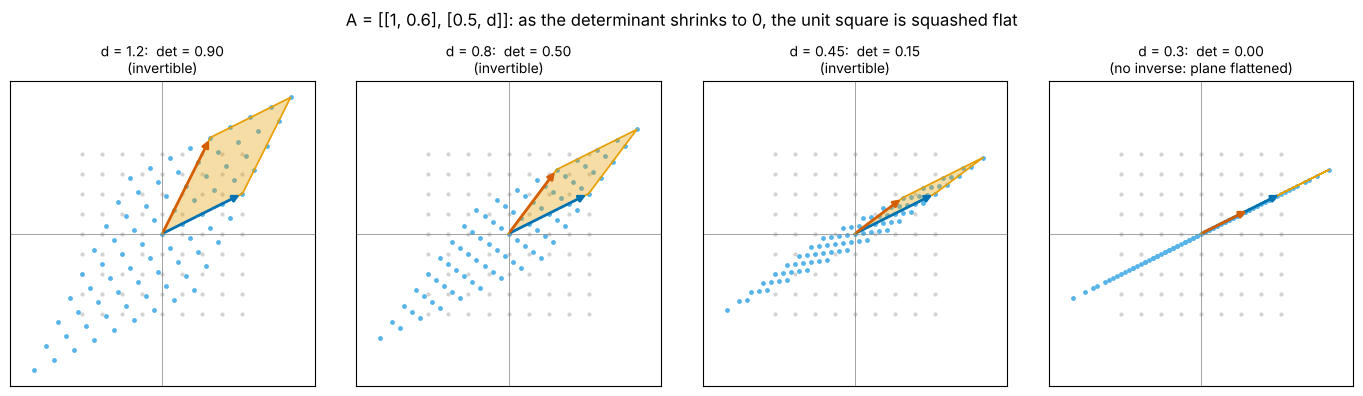

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, t_val in zip(axes, [1.2, 0.8, 0.45, 0.3]):
    M = np.array([[1.0, 0.6], [0.5, t_val]])
    draw_transform(ax, M, f'd = {t_val}:  det = {np.linalg.det(M):.2f}' + ('\n(no inverse: plane flattened)' if np.isclose(np.linalg.det(M), 0) else '\n(invertible)'), lim=1.9)
fig.suptitle('A = [[1, 0.6], [0.5, d]]: as the determinant shrinks to 0, the unit square is squashed flat', y=1.03)
plt.tight_layout()
plt.show()

#### Animation: the determinant as the area of the unit square's image

In [24]:
# INTERACTIVE ANIMATION -- the bottom-right entry d moves from 1.4 to -0.4
d_values = np.round(np.linspace(1.4, -0.4, 37), 2)
def det_traces(d):
    M = np.array([[1.0, 0.6], [0.5, d]])
    sq, pts = M @ unit_square, M @ lattice
    return M, [go.Scatter(x=pts[0], y=pts[1]), go.Scatter(x=sq[0], y=sq[1])]
M0, tr0 = det_traces(d_values[0])
fig_det = go.Figure([go.Scatter(x=tr0[0].x, y=tr0[0].y, mode='markers', marker=dict(color=PALETTE[5], size=5), name='lattice'),
                     go.Scatter(x=tr0[1].x, y=tr0[1].y, mode='lines', fill='toself', line=dict(color=PALETTE[4]), name='unit square')])
frames = []
for k, d in enumerate(d_values):
    M, tr = det_traces(d)
    frames.append(go.Frame(name=str(k), data=tr, layout=go.Layout(title=f'd = {d:+.2f}:  det = {np.linalg.det(M):+.2f}  (area of yellow shape = {abs(np.linalg.det(M)):.2f})')))
fig_det.frames = frames
buttons, sliders = play_pause_and_slider([f'{d:+.2f}' for d in d_values], prefix='d = ', duration=150)
fig_det.update_layout(title=f'd = {d_values[0]:+.2f}:  det = {np.linalg.det(M0):+.2f}', template='plotly_white', width=650, height=620,
                      xaxis=dict(range=[-2, 2]), yaxis=dict(range=[-2, 2], scaleanchor='x', scaleratio=1),
                      updatemenus=buttons, sliders=sliders)
fig_det.show(config=PLOTLY_CONFIG)

Watch the moment the determinant passes through 0 (at $d = 0.3$): the square collapses to a line segment, and as it turns negative the square comes back **mirror-flipped**. The sign of the determinant records orientation; its size records area.

# **Part 7: Affine Maps and Activation Functions — One Neural-Network Layer**

Lesson 2 added a bias to a single neuron: $z = \mathbf{w}\cdot\mathbf{x} + b$. For a whole population, each output neuron gets its own bias:

$$\mathbf{z} = \mathbf{W}\mathbf{x} + \mathbf{b}.$$

This is an **affine** map: a linear transformation followed by a shift. It is not linear (it sends $\mathbf{0}$ to $\mathbf{b}$, not to $\mathbf{0}$), but a trick makes it linear in one extra dimension. Append a 1 to the input and the bias as an extra column:

$$\begin{pmatrix}\mathbf{z}\\ 1\end{pmatrix} = \begin{pmatrix}\mathbf{W} & \mathbf{b}\\ \mathbf{0}^{\mathsf T} & 1\end{pmatrix}\begin{pmatrix}\mathbf{x}\\ 1\end{pmatrix}.$$

Computer graphics uses this to move objects; Lesson 5 uses the same column of ones for the intercept in regression.

Next comes the **nonlinear stage**. A neural-network layer, and a simple model of a population of neurons, applies a function $f$ to every entry of $\mathbf{z}$:

$$\mathbf{a} = f(\mathbf{W}\mathbf{x} + \mathbf{b}).$$

Here $\mathbf{z}$ is the **pre-activation** (it can be negative) and $\mathbf{a}$ is the **activation**, like a firing rate. Common choices of $f$, applied entry by entry:
- **ReLU**, $\max(0, z)$: zero below threshold, linear above, like a rate that cannot go negative;
- **sigmoid**, $1/(1 + e^{-z})$: squashes to $(0, 1)$, like a firing rate that saturates;
- **tanh**: squashes to $(-1, 1)$.

Affine W x + b          : [2. 1.]
Augmented matrix times (x, 1): [2. 1.]
Affine map sends 0 to   : [ 0.5 -1. ]  (a linear map would give 0)


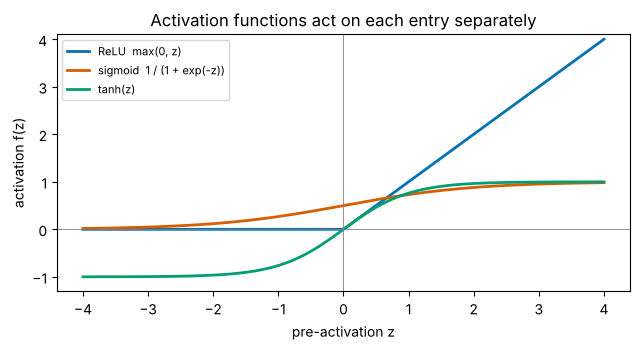

In [25]:
W_aff = np.array([[1.0, -0.5], [0.4, 1.2]])
b_aff = np.array([0.5, -1.0])
x_aff = np.array([2.0, 1.0])

W_aug = np.block([[W_aff, b_aff[:, None]], [np.zeros((1, 2)), np.ones((1, 1))]])   # shape (3, 3)
print("Affine W x + b          :", W_aff @ x_aff + b_aff)
print("Augmented matrix times (x, 1):", (W_aug @ np.append(x_aff, 1.0))[:2])
print("Affine map sends 0 to   :", W_aff @ np.zeros(2) + b_aff, " (a linear map would give 0)")

relu = lambda z: np.maximum(0.0, z)
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))

z_grid = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(z_grid, relu(z_grid), color=PALETTE[0], lw=2, label='ReLU  max(0, z)')
ax.plot(z_grid, sigmoid(z_grid), color=PALETTE[1], lw=2, label='sigmoid  1 / (1 + exp(-z))')
ax.plot(z_grid, np.tanh(z_grid), color=PALETTE[2], lw=2, label='tanh(z)')
ax.axhline(0, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
ax.set_xlabel('pre-activation z'); ax.set_ylabel('activation f(z)'); ax.set_ylim(-1.3, 4.1)
ax.set_title('Activation functions act on each entry separately')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Why the nonlinearity matters: stacked linear layers collapse

Two linear layers in a row are one linear layer (Part 4): $\mathbf{W}_2(\mathbf{W}_1\mathbf{x}) = (\mathbf{W}_2\mathbf{W}_1)\mathbf{x}$. A hundred stacked linear layers can do no more than a single matrix. Put a nonlinearity between them and the collapse no longer happens: $\mathbf{W}_2 f(\mathbf{W}_1\mathbf{x}) \neq (\mathbf{W}_2\mathbf{W}_1)\mathbf{x}$ in general. That is why deep networks, and real neural pathways, need nonlinear stages to compute anything a single matrix cannot.

The figure follows a grid of inputs through one layer: the affine map shears and shifts it, and ReLU then **folds** every negative coordinate onto an axis. No matrix can fold.

Two linear layers equal one matrix (W2 W1)? True
With ReLU between them, still equal?        False


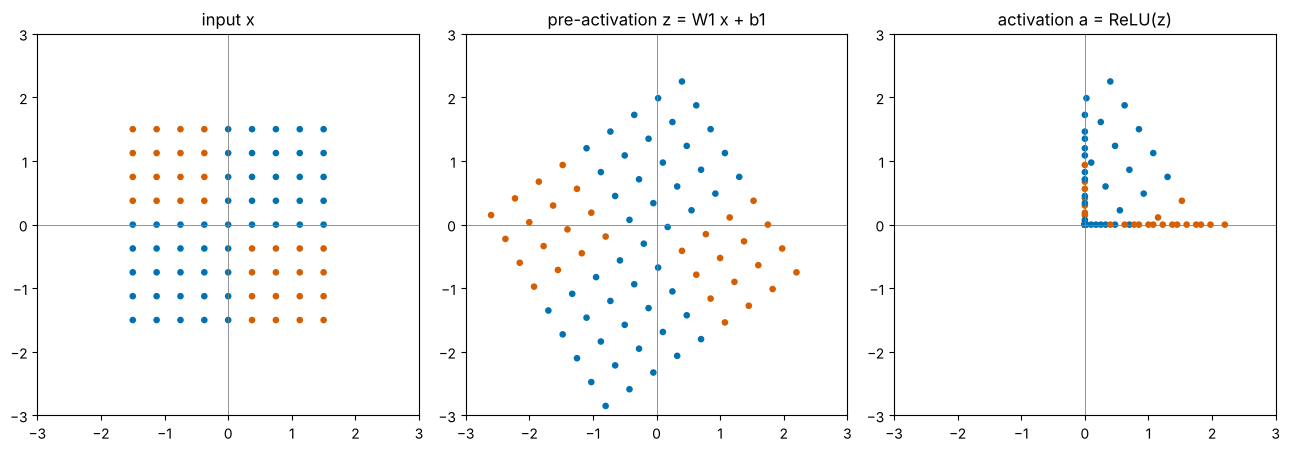

In [26]:
W1 = np.array([[1.0, -0.6], [0.7, 1.0]])
b1 = np.array([-0.2, -0.3])
W2 = np.array([[0.8, 0.5], [-0.4, 1.1]])

grid_in = 1.5 * lattice                                    # shape (2, 81)
pre = W1 @ grid_in + b1[:, None]                           # affine stage
post = relu(pre)                                           # nonlinear stage

x_probe = grid_in[:, :5]
linear_chain = W2 @ (W1 @ x_probe)
collapsed = (W2 @ W1) @ x_probe
with_relu = W2 @ relu(W1 @ x_probe)
print("Two linear layers equal one matrix (W2 W1)?", np.allclose(linear_chain, collapsed))
print("With ReLU between them, still equal?       ", np.allclose(with_relu, collapsed))

colours = np.where(grid_in[0] * grid_in[1] >= 0, PALETTE[0], PALETTE[1])   # colour points by input quadrant
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, P2, title in zip(axes, [grid_in, pre, post], ['input x', 'pre-activation z = W1 x + b1', 'activation a = ReLU(z)']):
    ax.scatter(P2[0], P2[1], s=14, c=colours)
    ax.axhline(0, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect('equal'); ax.set_title(title)
plt.tight_layout()
plt.show()

#### Animation: slide the bias and watch ReLU fold the grid

In [27]:
# INTERACTIVE ANIMATION -- the first bias entry b1[0] moves from -1.5 to 1.5
bias_values = np.round(np.linspace(-1.5, 1.5, 31), 2)
def layer_out(b0):
    return relu(W1 @ grid_in + np.array([b0, b1[1]])[:, None])
first_out = layer_out(bias_values[0])
fig_bias = go.Figure(go.Scatter(x=first_out[0], y=first_out[1], mode='markers', marker=dict(color=list(colours), size=7)))
fig_bias.frames = [go.Frame(name=str(k), data=[go.Scatter(x=layer_out(b0)[0], y=layer_out(b0)[1])],
                            layout=go.Layout(title=f'a = ReLU(W1 x + b),  b = ({b0:+.2f}, {b1[1]:+.2f})'))
                   for k, b0 in enumerate(bias_values)]
buttons, sliders = play_pause_and_slider([f'{b:+.2f}' for b in bias_values], prefix='b[0] = ', duration=120)
fig_bias.update_layout(title=f'a = ReLU(W1 x + b),  b = ({bias_values[0]:+.2f}, {b1[1]:+.2f})', template='plotly_white', width=640, height=620,
                       xaxis=dict(range=[-0.3, 4], title='activation of unit 1'), yaxis=dict(range=[-0.3, 4], title='activation of unit 2', scaleanchor='x', scaleratio=1),
                       updatemenus=buttons, sliders=sliders)
fig_bias.show(config=PLOTLY_CONFIG)

**Limitations.** A ReLU or sigmoid unit is a caricature of a neuron: real neurons have dynamics, adaptation and noise, and an artificial network's weight matrix is not a literal wiring diagram. And a sigmoid output between 0 and 1 is not automatically a calibrated probability.

# **Part 8: Translating Between Neural and Behavioural Space**

Two different vector spaces describe the same moment of a reaching experiment:
- **behavioural space**: the direction of hand movement, a 2-D unit vector $\mathbf{d} = (\cos\theta, \sin\theta)$;
- **neural space**: the firing rates of $N$ motor-cortex neurons, a vector $\mathbf{r}$ with $N$ entries.

A matrix can translate in each direction.

**Encoding (behaviour → neurons).** Lesson 2 found that motor-cortex neurons are cosine-tuned: $r_i = b_i + g_i\cos(\theta - \phi_i)$. Expanding the cosine, $g_i\cos(\theta - \phi_i) = g_i\cos\phi_i\cos\theta + g_i\sin\phi_i\sin\theta$, which is a dot product of $(g_i\cos\phi_i,\ g_i\sin\phi_i)$ with $\mathbf{d}$. Stack those rows into an $N\times2$ **encoding matrix** $\mathbf{E}$:

$$\mathbf{r} = \mathbf{b} + \mathbf{E}\,\mathbf{d}.$$

Cosine tuning *is* an affine map from a 2-D space into an $N$-dimensional one. $\mathbf{E}$ has rank 2, so without noise every population response lies on a flat 2-D sheet inside $N$-dimensional space.

**Decoding (neurons → behaviour).** A $2\times N$ **decoding matrix** $\mathbf{D}$ translates back: $\hat{\mathbf{d}} = \mathbf{D}(\mathbf{r} - \mathbf{b})$. The population vector of Lesson 2 is one such matrix: column $i$ of $\mathbf{D}$ is $\frac{2}{N}\,(\cos\phi_i,\ \sin\phi_i)/g_i$.

Encoding then decoding is the composition $\mathbf{D}\mathbf{E}$, a $2\times2$ matrix. **A perfect decoder has $\mathbf{D}\mathbf{E} = \mathbf{I}$**: going into neural space and back changes nothing. We first check this on a simulated population, where we control everything.

In [28]:
N_sim = 60
phi_sim = RNG.uniform(0, 2 * np.pi, N_sim)                 # preferred directions, radians
g_sim = RNG.uniform(5, 20, N_sim)                          # depths of modulation, spikes/s
b_sim = RNG.uniform(10, 40, N_sim)                         # baselines, spikes/s
U_sim = np.column_stack([np.cos(phi_sim), np.sin(phi_sim)])   # shape (60, 2): unit preferred directions
E_sim = g_sim[:, None] * U_sim                             # shape (60, 2): encoding matrix, spikes/s
D_sim = (2 / N_sim) * (U_sim / g_sim[:, None]).T           # shape (2, 60): population-vector decoder

print("E_sim shape:", E_sim.shape, " rank:", np.linalg.matrix_rank(E_sim))
print("D_sim shape:", D_sim.shape)
print("D E =\n", np.round(D_sim @ E_sim, 3), "\n(close to the identity: decoding undoes encoding)")

# A hand moving round a circle and back, 300 time steps
t_steps = np.linspace(0, 2 * np.pi, 300)
theta_true = t_steps + 0.6 * np.sin(2 * t_steps)                      # movement direction over time
d_true = np.vstack([np.cos(theta_true), np.sin(theta_true)])          # shape (2, 300): behavioural space
r_sim = b_sim[:, None] + E_sim @ d_true + RNG.normal(0, 4, (N_sim, 300))   # shape (60, 300): neural space, plus noise
d_hat = D_sim @ (r_sim - b_sim[:, None])                              # shape (2, 300): decoded back to behaviour
theta_hat = np.arctan2(d_hat[1], d_hat[0])
err_deg = np.degrees((theta_hat - theta_true + np.pi) % (2 * np.pi) - np.pi)
print(f"Decoding error over time: median {np.median(np.abs(err_deg)):.1f} deg")

E_sim shape: (60, 2)  rank: 2
D_sim shape: (2, 60)
D E =
 [[ 1.013 -0.021]
 [-0.021  0.987]] 
(close to the identity: decoding undoes encoding)
Decoding error over time: median 2.7 deg


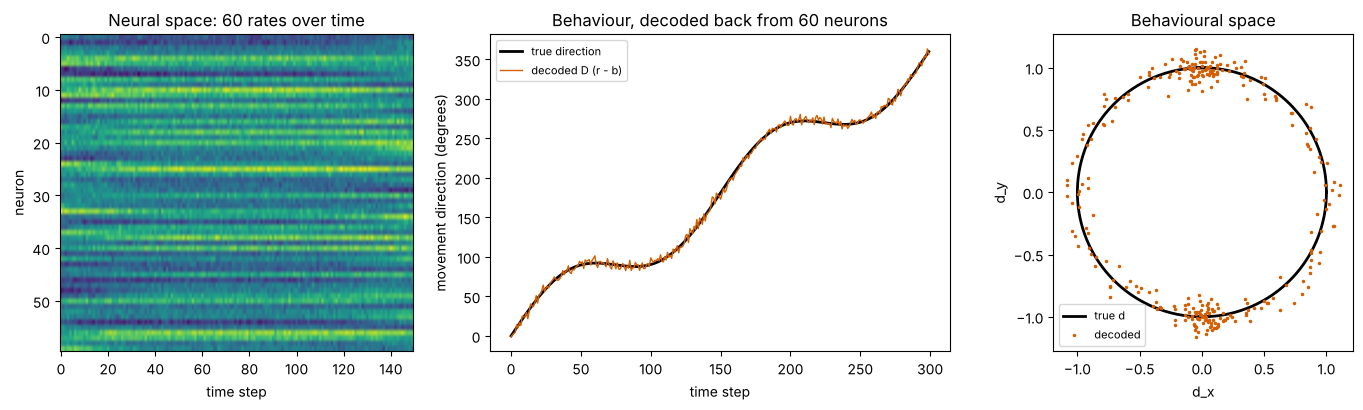

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1.3, 1]})
ax = axes[0]
ax.imshow(r_sim[:, :150], aspect='auto', cmap='viridis')
ax.set_xlabel('time step'); ax.set_ylabel('neuron'); ax.set_title('Neural space: 60 rates over time')
ax = axes[1]
ax.plot(np.degrees(np.unwrap(theta_true)), color='black', lw=2, label='true direction')
ax.plot(np.degrees(np.unwrap(theta_hat)), color=PALETTE[1], lw=1, label='decoded D (r - b)')
ax.set_xlabel('time step'); ax.set_ylabel('movement direction (degrees)'); ax.set_title('Behaviour, decoded back from 60 neurons')
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(d_true[0], d_true[1], color='black', lw=2, label='true d')
ax.plot(d_hat[0], d_hat[1], '.', color=PALETTE[1], ms=3, label='decoded')
ax.set_aspect('equal'); ax.set_xlabel('d_x'); ax.set_ylabel('d_y'); ax.set_title('Behavioural space')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The decoded direction follows the true one closely, with noise. The matrices did all the work: $\mathbf{E}$ embedded a 2-D behaviour into 60-D neural space, and $\mathbf{D}$ compressed it back.

Why is $\mathbf{D}\mathbf{E}$ close to $\mathbf{I}$? Entry by entry, $\mathbf{D}\mathbf{E} = \frac{2}{N}\sum_i \mathbf{u}_i\mathbf{u}_i^{\mathsf T}$, an average over neurons of $2\begin{pmatrix}\cos^2\phi_i & \cos\phi_i\sin\phi_i\\ \cos\phi_i\sin\phi_i & \sin^2\phi_i\end{pmatrix}$. When preferred directions are spread evenly, $\cos^2$ and $\sin^2$ each average $\tfrac12$ and the cross term averages 0, which gives $\mathbf{I}$ (the study notes give the details). If the preferred directions are **not** evenly spread, $\mathbf{D}\mathbf{E}$ is not $\mathbf{I}$, and the decoder distorts behavioural space. The real data in Part 9 do exactly that.

# **Part 9: Mini-Lab — Encoding and Decoding Real Motor Cortex**

This mini-lab returns to the recording from Lesson 2: 171 neurons in a monkey's primary motor cortex during centre-out reaches to eight targets ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); shared through the [DREAM database on CRCNS](https://crcns.org/data-sets/movements/dream), packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)). The file (1.3 MB) downloads the first time the cell runs.

**Plan.**
1. Fit each neuron's cosine tuning on the **first half** of the session (the Lesson 2 method), and stack the fits into the encoding matrix $\mathbf{E}$.
2. Check its rank, and how much of the real tuning a rank-2 map explains.
3. Build the population-vector decoder $\mathbf{D}$ and compute $\mathbf{D}\mathbf{E}$.
4. Use the inverse of $\mathbf{D}\mathbf{E}$ to correct the decoder, and test both on the **second half**.

In [30]:
# Step 1: load the data and fit cosine tuning on the first half (as in Lesson 2)
import os, urllib.request
from scipy.io import loadmat

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
rates = m1['spikes'].astype(float) / 0.05                 # shape (171, 15536): (neuron, 50 ms bin), spikes/s
hand_vel = m1['handVel'][:2]                               # shape (2, 15536): hand velocity, m/s
move_angle = np.arctan2(hand_vel[1], hand_vel[0])          # shape (15536,): movement direction, radians
moving = np.linalg.norm(hand_vel, axis=0) > 0.1            # faster than 10 cm/s
direction_index = np.round((np.degrees(move_angle) % 360) / 45).astype(int) % 8
first_half = np.arange(rates.shape[1]) < rates.shape[1] // 2
theta8 = np.radians(np.arange(0, 360, 45))                  # the eight reach directions
D8 = np.vstack([np.cos(theta8), np.sin(theta8)])            # shape (2, 8): the eight directions as unit vectors

def tuning_table(use):
    return np.stack([rates[:, use & moving & (direction_index == k)].mean(axis=1) for k in range(8)], axis=1)

tuning_fit, tuning_test = tuning_table(first_half), tuning_table(~first_half)   # each (171, 8), spikes/s
base_all = tuning_fit.mean(axis=1)                                              # baselines, shape (171,)
centred = tuning_fit - base_all[:, None]
E_all = centred @ D8.T / 4                     # shape (171, 2): row i = g_i (cos phi_i, sin phi_i), the Lesson 2 fit
model_all = E_all @ D8                         # cosine model of every centred tuning curve, shape (171, 8)
norms = np.linalg.norm(centred, axis=1) * np.linalg.norm(model_all, axis=1)
fit_sim = np.where(norms > 0, (centred * model_all).sum(axis=1) / np.where(norms > 0, norms, 1), 0.0)
tuned = fit_sim > 0.8

E = E_all[tuned]                               # encoding matrix of the well-tuned neurons
base = base_all[tuned]
N = E.shape[0]
print(f"Well-tuned neurons: {N} of {rates.shape[0]};  E shape {E.shape}: (neuron, behavioural axis), spikes/s")

Well-tuned neurons: 82 of 171;  E shape (82, 2): (neuron, behavioural axis), spikes/s


`E_all = centred @ D8.T / 4` is the Lesson 2 fit written as one matrix product: each row of `centred` is dotted with the cosine and sine vectors of the eight directions, and divided by 4. All 171 fits happen at once.

In [31]:
# Step 2: rank, and how much of the real tuning a rank-2 map captures
C_fit = centred[tuned]                         # shape (N, 8): real centred tuning, first half
C_test = tuning_test[tuned] - base[:, None]    # shape (N, 8): real centred tuning, second half
model = E @ D8                                 # shape (N, 8): what the rank-2 encoding predicts
print("rank of E:", np.linalg.matrix_rank(E), "   rank of the real centred tuning (8 directions):", np.linalg.matrix_rank(C_fit))
frac_fit = 1 - np.linalg.norm(C_fit - model)**2 / np.linalg.norm(C_fit)**2
frac_test = 1 - np.linalg.norm(C_test - model)**2 / np.linalg.norm(C_test)**2
print(f"Fraction of the tuning's variation explained by the rank-2 map: first half {frac_fit:.2f}, second half {frac_test:.2f}")

rank of E: 2    rank of the real centred tuning (8 directions): 7
Fraction of the tuning's variation explained by the rank-2 map: first half 0.90, second half 0.67


The eight real population patterns span 7 dimensions, not 2. (Not 8: centring makes them sum to zero, so one is a combination of the others.) But most of their variation lies in just two directions: a rank-2 map explains about 90% of it on the data it was fitted to, and about two-thirds on the held-out half. The rest is noise and tuning that is not quite cosine. A low-rank matrix is a good, but not perfect, description of how this population encodes direction.

In [32]:
# Step 3: the population-vector decoder and the composite D E
g = np.linalg.norm(E, axis=1)                  # depths of modulation, spikes/s
U = E / g[:, None]                             # unit preferred directions, shape (N, 2)
D = (2 / N) * (U / g[:, None]).T               # shape (2, N): population-vector decoder
DE = D @ E
print("D shape:", D.shape, "\nD E =\n", np.round(DE, 3))
pd_deg = np.degrees(np.arctan2(U[:, 1], U[:, 0])) % 180
print(f"Preferred directions within 30 deg of the left-right axis: {np.mean((pd_deg < 30) | (pd_deg > 150)):.0%}  (an even spread would give 33%)")

D shape: (2, 82) 
D E =
 [[ 1.194 -0.009]
 [-0.009  0.806]]
Preferred directions within 30 deg of the left-right axis: 44%  (an even spread would give 33%)


$\mathbf{D}\mathbf{E}$ is not the identity: it stretches the left–right axis by about 1.19 and shrinks the up–down axis to about 0.81. The reason is in the last line: more of these neurons prefer left or right than up or down, so the population over-represents the horizontal axis. This is the matrix explanation of the pull towards left–right that Lesson 2's Exercise 7 found.

The fix is Part 6: undo the distortion with its inverse. The **corrected decoder** is $\mathbf{D}_c = (\mathbf{D}\mathbf{E})^{-1}\mathbf{D}$, which satisfies $\mathbf{D}_c\mathbf{E} = \mathbf{I}$ exactly.

In [33]:
# Step 4: correct the decoder and test both on the held-out half
D_corr = np.linalg.inv(DE) @ D
print("D_corr E =\n", np.round(D_corr @ E, 3))

def wrap_deg(a):
    return (np.degrees(a) + 180) % 360 - 180

out_pv = D @ C_test                             # decoded direction vectors, shape (2, 8)
out_corr = D_corr @ C_test
err_pv = wrap_deg(np.arctan2(out_pv[1], out_pv[0]) - theta8)
err_corr = wrap_deg(np.arctan2(out_corr[1], out_corr[0]) - theta8)
print("\nTrue direction (deg):", np.degrees(theta8).astype(int))
print("Error, D        :", np.round(err_pv, 1), f"  mean |error| {np.abs(err_pv).mean():.1f} deg")
print("Error, D_corr   :", np.round(err_corr, 1), f"  mean |error| {np.abs(err_corr).mean():.1f} deg")

# Bin-by-bin decoding on the held-out half (rates averaged over 5 bins = 250 ms)
smooth = np.apply_along_axis(lambda x: np.convolve(x, np.ones(5) / 5, mode='same'), 1, rates[tuned])
test_bins = np.flatnonzero(~first_half & moving)
bin_out = D_corr @ (smooth[:, test_bins] - base[:, None])
bin_err = wrap_deg(np.arctan2(bin_out[1], bin_out[0]) - move_angle[test_bins])
print(f"\nSingle 250 ms windows ({test_bins.size} moving bins): median |error| {np.median(np.abs(bin_err)):.0f} deg, within 45 deg {np.mean(np.abs(bin_err) < 45):.0%}")

D_corr E =
 [[1. 0.]
 [0. 1.]]

True direction (deg): [  0  45  90 135 180 225 270 315]
Error, D        : [ -1.9 -21.   -0.7  15.4  13.6  -0.9 -10.4   7.1]   mean |error| 8.9 deg
Error, D_corr   : [ -2.2 -11.2  -0.9   5.1  20.3  10.   -7.5  -4.1]   mean |error| 7.7 deg

Single 250 ms windows (1194 moving bins): median |error| 20 deg, within 45 deg 82%


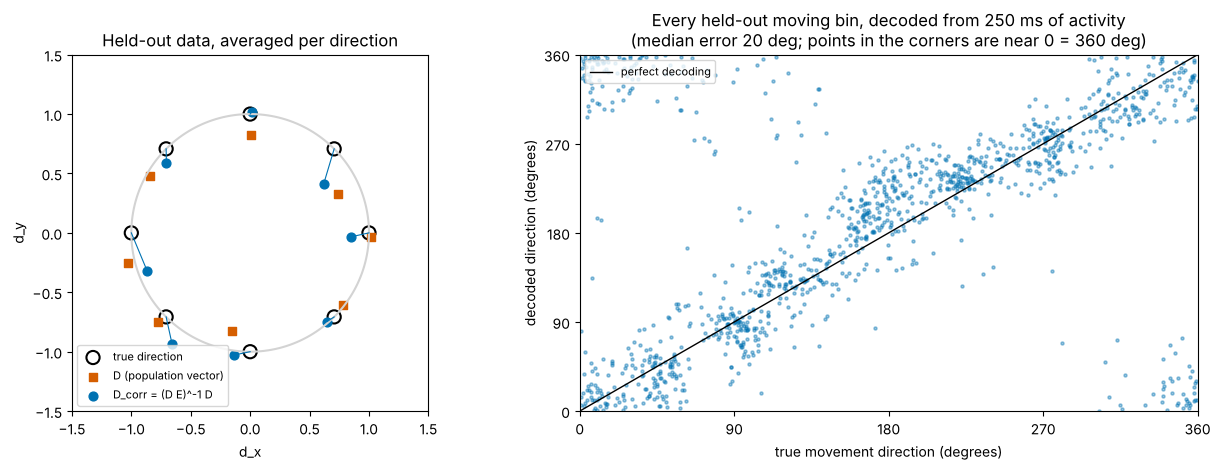

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.1]})
ax = axes[0]
circle = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(circle), np.sin(circle), color='lightgrey')
ax.scatter(D8[0], D8[1], s=90, facecolors='none', edgecolors='black', lw=1.5, label='true direction')
ax.scatter(out_pv[0], out_pv[1], color=PALETTE[1], marker='s', s=40, label='D (population vector)')
ax.scatter(out_corr[0], out_corr[1], color=PALETTE[0], s=40, label='D_corr = (D E)^-1 D')
for k in range(8):
    ax.plot([D8[0, k], out_corr[0, k]], [D8[1, k], out_corr[1, k]], color=PALETTE[0], lw=0.8)
ax.set_aspect('equal'); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('d_x'); ax.set_ylabel('d_y')
ax.set_title('Held-out data, averaged per direction')
ax.legend(fontsize=8, loc='lower left')

ax = axes[1]
true_deg = np.degrees(move_angle[test_bins]) % 360
dec_deg = np.degrees(np.arctan2(bin_out[1], bin_out[0])) % 360
ax.scatter(true_deg, dec_deg, s=5, alpha=0.4, color=PALETTE[0])
ax.plot([0, 360], [0, 360], color='black', lw=1, label='perfect decoding')
ax.set_xlim(0, 360); ax.set_ylim(0, 360); ax.set_xticks(range(0, 361, 90)); ax.set_yticks(range(0, 361, 90))
ax.set_xlabel('true movement direction (degrees)'); ax.set_ylabel('decoded direction (degrees)')
ax.set_title(f'Every held-out moving bin, decoded from 250 ms of activity\n(median error {np.median(np.abs(bin_err)):.0f} deg; points in the corners are near 0 = 360 deg)')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

#### Interactive version: decoded directions on held-out data

In [35]:
fig_dec = go.Figure()
fig_dec.add_trace(go.Scatter(x=np.cos(circle), y=np.sin(circle), mode='lines', line=dict(color='lightgrey'), hoverinfo='skip', showlegend=False))
fig_dec.add_trace(go.Scatter(x=D8[0], y=D8[1], mode='markers', name='true', marker=dict(size=14, symbol='circle-open', color='black', line=dict(width=2)),
                             text=[f'{a} deg' for a in np.degrees(theta8).astype(int)], hovertemplate='true %{text}<extra></extra>'))
for out, err, name, colour, sym in [(out_pv, err_pv, 'D', PALETTE[1], 'square'), (out_corr, err_corr, 'D_corr', PALETTE[0], 'circle')]:
    fig_dec.add_trace(go.Scatter(x=out[0], y=out[1], mode='markers', name=name, marker=dict(color=colour, size=10, symbol=sym),
                                 text=[f'true {a} deg, error {e:+.1f} deg' for a, e in zip(np.degrees(theta8).astype(int), err)],
                                 hovertemplate='%{text}<extra>' + name + '</extra>'))
fig_dec.update_layout(title='Decoded directions on the held-out half (hover for errors)', template='plotly_white', width=620, height=600,
                      xaxis=dict(range=[-1.5, 1.5], title='d_x'), yaxis=dict(range=[-1.5, 1.5], title='d_y', scaleanchor='x', scaleratio=1))
fig_dec.show(config=PLOTLY_CONFIG)

**Interpretation.** Motor cortex encodes movement direction close to a rank-2 linear map: an encoding matrix with one row per neuron explains most of how these 82 well-tuned neurons respond to the eight directions. Decoding is a second matrix, and $\mathbf{D}\mathbf{E}$ says exactly how faithfully the round trip works. Here it revealed a systematic stretch along the left–right axis, caused by the uneven spread of preferred directions. Inverting that $2\times2$ matrix removed the stretch, and the corrected decoder pulls three of the four diagonal directions (45°, 135°, 315°) back towards their true angles. But it makes 180° and 225° worse, and the mean error on held-out data falls only from about 9° to about 8°. Most of the remaining error is noise and non-cosine tuning, not the systematic stretch, and a correction for distortion cannot remove noise. Bin by bin, 250 ms of activity gives the direction to within about 20° at the median.

**Limitations.** The encoding matrix uses direction only, ignoring speed, position and force, which also drive these neurons. The tuning was measured from averages over many bins; single bins are much noisier. $(\mathbf{D}\mathbf{E})^{-1}\mathbf{D}$ makes the decoder exact *for the model*, not the best possible decoder for real data: fitting the decoder directly to data by least squares is Lesson 5. And decoding well shows the information is in the population, not that the brain reads it out this way.

# **Part 10: Where This Appears in Neuroscience and Machine Learning**

| Matrix transformation | Neuroscience | Machine learning |
|---|---|---|
| $\mathbf{z} = \mathbf{W}\mathbf{r}$ | synaptic input to a population | the linear part of a layer |
| Composition $\mathbf{W}_2\mathbf{W}_1$ | feedforward pathways (retina → LGN → V1) | stacked layers |
| Low rank | low-dimensional neural manifolds; low-rank recurrent networks | bottleneck layers, autoencoders, low-rank adaptation (LoRA) |
| Projection | read-out along a task axis (Lesson 2) | dimensionality reduction (Lesson 7, PCA) |
| Rotation | rotational dynamics in motor cortex | data augmentation; rotation-invariant features |
| Inverse, $\mathbf{D}\mathbf{E} = \mathbf{I}$ | brain–computer interfaces decode intended movement | inverting a model; Lesson 5 solves $\mathbf{A}\mathbf{x} = \mathbf{b}$ |
| $\mathbf{a} = f(\mathbf{W}\mathbf{x} + \mathbf{b})$ | rate model of a population | one neural-network layer |
| $\mathbf{Z} = \mathbf{X}\mathbf{W}^{\mathsf T}$ | sending every trial through a model at once | batched forward pass on a GPU |

Brain–computer interfaces that let paralysed people move a cursor or a robotic arm decode intended movement from motor-cortex activity with a matrix very like $\mathbf{D}$. Early systems used the population vector; modern ones fit the decoder to data (Lesson 5) and add dynamics.

# **Part 11: Summary and Lesson 5 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Matrix–vector product | $y_i = \sum_j a_{ij}x_j$, `A @ x` | rows: dot products; columns: weighted mix |
| Shape rule | $(m\times k)(k\times n) = (m\times n)$ | inner sizes match, outer sizes survive |
| Matrix–matrix product | $c_{ij} = (\text{row } i)\cdot(\text{col } j)$ | $\mathbf{A}$ acting on every column of $\mathbf{B}$ |
| Batch | $\mathbf{Z} = \mathbf{X}\mathbf{W}^{\mathsf T}$ | one trial per row in, one per row out |
| Associative, not commutative | $(\mathbf{AB})\mathbf{C} = \mathbf{A}(\mathbf{BC})$, $\mathbf{AB}\neq\mathbf{BA}$ | grouping is free; order is not |
| Linear map | columns $= \mathbf{A}\mathbf{e}_j$ | a matrix is decided by where it sends the basis |
| Composition | $\mathbf{R}(\mathbf{S}\mathbf{x}) = (\mathbf{RS})\mathbf{x}$ | rightmost acts first |
| Rank | dimension of the image | $\le\min(m,n)$; chains have the rank of the narrowest link |
| Determinant ($2\times2$) | $ad - bc$ | area factor; 0 means no inverse |
| Inverse | $\mathbf{A}^{-1}\mathbf{A} = \mathbf{I}$, $(\mathbf{AB})^{-1} = \mathbf{B}^{-1}\mathbf{A}^{-1}$ | undo in reverse order |
| Layer | $\mathbf{a} = f(\mathbf{W}\mathbf{x} + \mathbf{b})$ | affine, then nonlinear; without $f$, layers collapse |
| Encoding / decoding | $\mathbf{r} = \mathbf{b} + \mathbf{E}\mathbf{d}$, $\hat{\mathbf{d}} = \mathbf{D}(\mathbf{r} - \mathbf{b})$ | a perfect round trip has $\mathbf{DE} = \mathbf{I}$ |

**Lesson 5** turns the question around. Here we knew the matrix and the input and computed the output. Next we know the output and the matrix and want the input, solving $\mathbf{A}\mathbf{x} = \mathbf{b}$, or we know inputs and outputs and want the matrix that best connects them. That is **least squares**, and it is how real decoders, encoding models and regression lines are fitted to data.